# Gravitational Waves

Zwei Blicke auf Gravitationswellen mit echten Daten: das erste gemessene Ereignis, GW150914, von den Rohdaten der beiden LIGO-Detektoren bis zur Chirp-Masse, und der ganze Katalog mit fast 400 bestätigten Ereignissen, ihren Massen, Entfernungen und dem Auswahleffekt. Die Daten kommen vom Gravitational Wave Open Science Center (GWOSC), die Rohdaten über die Bibliothek gwpy; Downloads landen in `data/gravitational_waves/`. Der Code steht in [`code/gravitational_waves/`](https://github.com/deltorobarba/science/tree/main/code/gravitational_waves) (`gw150914.py` für das erste Ereignis, `gwtc.py` für den Katalog, dazu `gwdata.py` für den Cache); hier stehen nur die Aufrufe und die Bilder. Die Funktionen eines Moduls reichen ihre Zwischenergebnisse weiter und laufen deshalb in der Reihenfolge des Notebooks.

**Der rote Faden**

Eine Gravitationswelle ändert die Arme eines Detektors um weniger als ein Hundertstel eines Protonendurchmessers. Beide Teile zeigen, wie man ein so kleines Signal aus dem Rauschen holt und was es über die Quelle verrät.

- **Schritte 1 bis 8, GW150914:** ein Ereignis, Schritt für Schritt. In den Rohdaten ist das Signal unsichtbar; Rauschspektrum, Whitening und Zeit-Frequenz-Bild machen es sichtbar, und aus dem Anstieg der Frequenz folgt die Chirp-Masse.
- **Schritte 9 bis 17, Katalog:** 284 Ereignisse mit Parametern. Massen, Massenlücken und Entfernungen, die Reichweite der Detektoren aus den Daten selbst und die Korrektur des Auswahleffekts.

Die gemeinsame Lehre: Was man misst, hängt davon ab, was man sehen kann. Bei einem Ereignis bestimmt das Rauschspektrum, welche Frequenzen zählen; im Katalog bestimmt die Reichweite der Detektoren, welche Massen überhaupt hineinkommen.

In [1]:
import sys
import subprocess
import urllib.request
import importlib.util
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()   # lokal liegt das Notebook in experiments/
CODE = ROOT / "code" / "gravitational_waves"
if "google.colab" in sys.modules:                            # in Colab: Pakete installieren, Code aus dem Repository holen
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gwpy", "gwosc"], check=True)
    if not CODE.exists():
        CODE.mkdir(parents=True)
        for f in ["gwdata.py", "gw150914.py", "gwtc.py"]:
            urllib.request.urlretrieve(f"https://raw.githubusercontent.com/deltorobarba/science/main/code/gravitational_waves/{f}", CODE / f)
elif importlib.util.find_spec("gwpy") is None or importlib.util.find_spec("gwosc") is None:
    raise ImportError("Es fehlen gwpy oder gwosc; lokal selbst installieren (conda-forge)")
sys.path.insert(0, str(CODE))      # Ordner direkt importieren ("code" ist auch ein Modul der Standardbibliothek)

import gw150914, gwtc

**1. GW150914: die Rohdaten von LIGO**

Am 14. September 2015 maßen die beiden LIGO-Detektoren in Hanford (H1) und Livingston (L1) zum ersten Mal direkt eine Gravitationswelle: das Signal zweier schwarzer Löcher von etwa 36 und 29 Sonnenmassen, die in rund 410 Mpc Entfernung verschmolzen. Die Welle änderte die 4 km langen Arme um etwa 4·10⁻¹⁸ m, weniger als ein Hundertstel eines Protonendurchmessers; 2017 gab es dafür den Nobelpreis. Geladen werden 32 Sekunden um das Ereignis aus beiden Detektoren, 4096 Werte pro Sekunde, vom Gravitational Wave Open Science Center (GWOSC) über die Bibliothek gwpy.

Die Ausgabe gibt die GPS-Zeit des Ereignisses, 1126259462.4 (Sekunden seit dem 6. Januar 1980, ohne Schaltsekunden), und bestätigt für beide Detektoren 32 s mit 4096 Hz.

In [2]:
gw150914.load()

GPS-Zeit des Ereignisses: 1126259462.4


H1: 32 s, 4096 Hz


L1: 32 s, 4096 Hz


**2. Rohdaten**

Der Strain, die relative Längenänderung ΔL/L, beider Detektoren über die ganzen 32 Sekunden, ohne jede Bearbeitung.

Die Ausschläge erreichen etwa ±0.5·10⁻¹⁸, das Signal hat nur etwa 10⁻²¹. Bei t = 0 ist deshalb nichts zu sehen: Das Rauschen ist mehrere hundertmal größer und besteht vor allem aus tiefen Frequenzen, den langsamen Wellen des Bodens. L1 liegt wegen solcher langsamen Schwankungen um etwa −1·10⁻¹⁸.

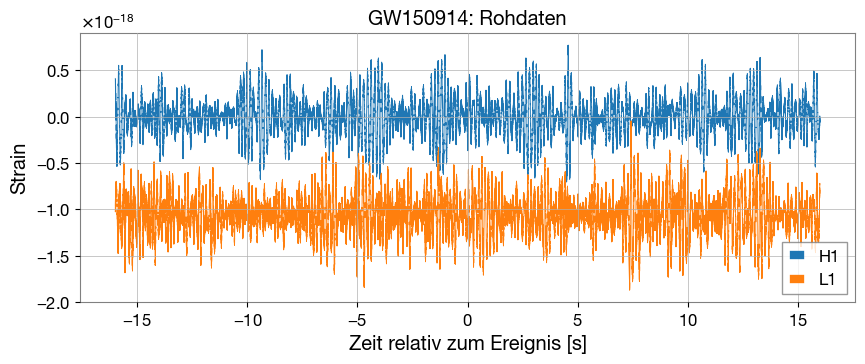

In [3]:
gw150914.raw_data()

**3. Rauschspektrum**

Die Amplitudenspektraldichte (ASD) gibt die Stärke des Rauschens pro Frequenz; je tiefer die Kurve, desto empfindlicher der Detektor. Geschätzt wird sie aus Abschnitten von 4 s, die sich um 2 s überlappen (Welch-Verfahren).

Unter 20 Hz steigt das Rauschen steil an (seismisch), zwischen etwa 50 und 500 Hz liegt es am tiefsten, bei rund 10⁻²³/√Hz, darüber steigt es langsam wieder (Schrotrauschen). Die schmalen Spitzen sind feste Störungen: 60 Hz und Vielfache vom Stromnetz, die Violin-Moden der Spiegelaufhängung um 500 Hz und Kalibrationslinien. Das Signal liegt mit 35 bis 250 Hz im empfindlichsten Bereich.

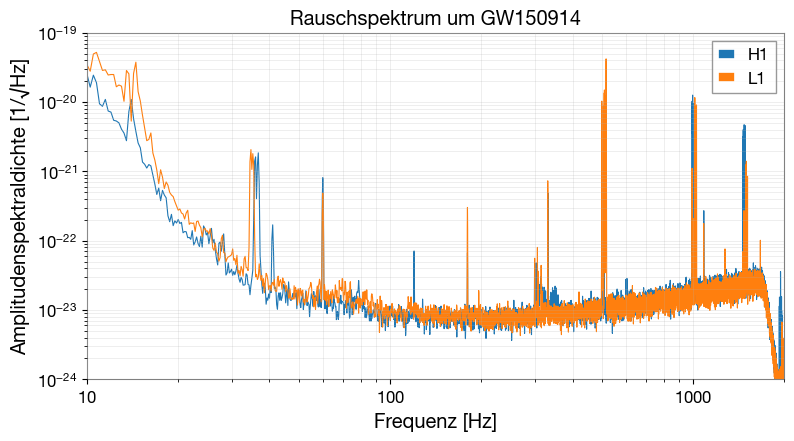

In [4]:
gw150914.noise_spectrum()

**4. Whitening und Bandpass**

Jede Frequenz wird durch ihr Rauschen geteilt (Whitening), danach bleiben nur 35 bis 350 Hz. L1 wird um 6.9 ms verschoben und mit −1 multipliziert: Ein echtes Signal muss beide Detektoren innerhalb der Lichtlaufzeit von 10 ms treffen, und L1 ist gegenüber H1 anders ausgerichtet.

Bis etwa −0.05 s schwanken beide Kurven unabhängig um null. Danach schwingen sie im Gleichtakt, immer schneller und stärker, bis etwa 2.5 Rauscheinheiten kurz nach t = 0, dann bricht das Signal ab: Einspiralen, Verschmelzen, Ausschwingen des neuen schwarzen Lochs. Dass beide Kurven nach Verschiebung und Vorzeichenwechsel übereinanderliegen, ist der stärkste einfache Hinweis auf eine echte Welle.

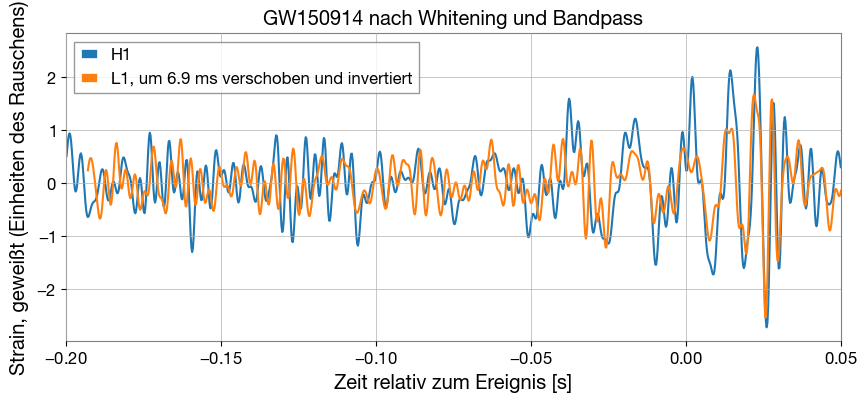

In [5]:
gw150914.whitened()

**5. Zeit-Frequenz-Bild**

Die Q-Transformation zerlegt das Signal mit Wellenpaketen fester Schwingungszahl in Zeit und Frequenz, hier für 0.35 s um das Ereignis von 20 bis 500 Hz. Die Farbe ist die normierte Energie: im Rauschen um 1, beim Signal über 25.

Das Signal ist das gelbe, nach oben gekrümmte Band, der Chirp: Es beginnt bei etwa −0.08 s mit 35 Hz und steigt in rund 0.1 s auf über 250 Hz. Von 35 bis 150 Hz sind das etwa acht Schwingungen der Welle, also vier Umläufe des Paares. Aus der Krümmung des Bandes folgt im nächsten Schritt die Masse.

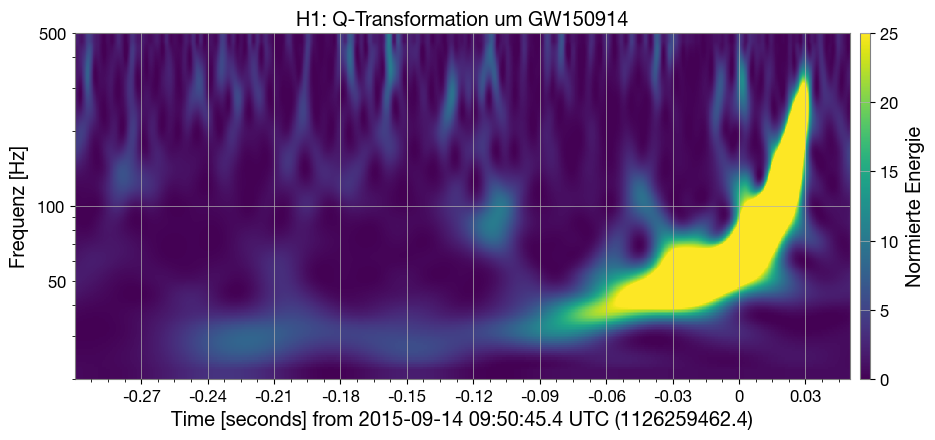

In [6]:
gw150914.spectrogram()

**6. Die Chirp-Masse**

Den Frequenzanstieg bestimmt allein die Chirp-Masse (m₁m₂)^(3/5)/(m₁+m₂)^(1/5); bei zwei gleichen Massen m ist sie 0.87 m. Für jede Chirp-Masse von 15 bis 60 Sonnenmassen und jede Verschmelzungszeit wird die Newtonsche Chirp-Kurve in das Zeit-Frequenz-Bild gelegt und die mittlere Energie entlang der Kurve gemessen; die hellste Kurve gewinnt.

H1 ergibt 34.5 Sonnenmassen und eine Verschmelzung 30 ms nach der Katalogzeit. Der helle Bereich ist ein schräges Band: Eine spätere Verschmelzung lässt sich teilweise durch eine kleinere Masse ausgleichen. Die beste Kurve folgt dem Signal bis etwa 90 Hz; den steilen letzten Anstieg lässt die Suche aus, weil die Newtonsche Formel dort nicht mehr gilt.

H1: Chirp-Masse im Detektorsystem 34.5 Sonnenmassen, Verschmelzung bei 30 ms


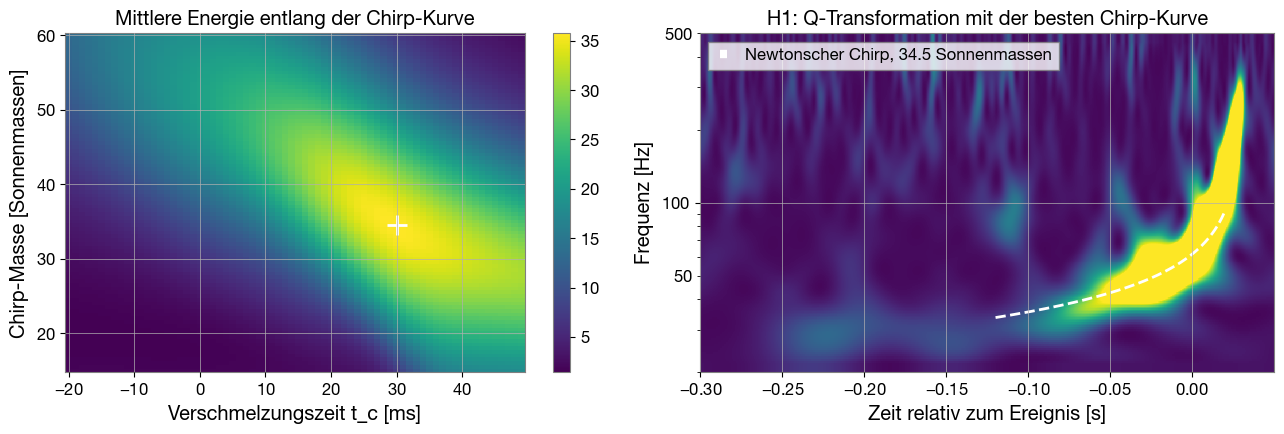

In [7]:
gw150914.chirp_mass()

**7. Wie sicher ist die Masse?**

Dieselbe Suche für beide Detektoren und für zwei Zeitbereiche vor der Verschmelzung, bis 10 ms und bis 20 ms davor.

Der Bereich nahe an der Verschmelzung gibt in beiden Detektoren 34.5 Sonnenmassen, der frühere 32.5 (H1) und 31.0 (L1). Nahe der Verschmelzung gilt die Newtonsche Formel am wenigsten. Mittelwert und Streuung, 33.1 ± 1.5 Sonnenmassen, sind die eigene Messung; die Streuung erfasst Bereich und Rauschen, nicht die Grenzen des Modells.

In [8]:
gw150914.robustness()

H1, tau von 0.01 bis 0.15 s: 34.5 Sonnenmassen


H1, tau von 0.02 bis 0.2 s: 32.5 Sonnenmassen


L1, tau von 0.01 bis 0.15 s: 34.5 Sonnenmassen


L1, tau von 0.02 bis 0.2 s: 31.0 Sonnenmassen
Eigene Messung: 33.1 ± 1.5 Sonnenmassen (Mittelwert und Streuung der vier Werte)


**8. Vergleich mit dem Katalog**

Der neueste Katalogeintrag gibt die Chirp-Masse im Ruhesystem der Quelle und die Rotverschiebung z. Im Detektor erscheinen Massen um (1 + z) größer; erst dieser Wert ist mit der eigenen Messung vergleichbar.

Der Katalog gibt 27.9 Sonnenmassen bei z = 0.10, also 30.7 im Detektor. Die eigene Messung liegt 8 % darüber, gut eineinhalb Streuungen. Ein Teil davon kommt von den letzten Umläufen, die die Newtonsche Formel nicht beschreibt; die Werte aus dem früheren Bereich liegen näher am Katalog. Für eine Methode, die nur die Frequenz in niedrigster Ordnung nutzt, sind 8 % gut.

In [9]:
gw150914.catalog_check()

Katalog (GW150914-v4): Chirp-Masse der Quelle 27.9, Rotverschiebung z = 0.10
Katalog im Detektorsystem, (1 + z) · M: 30.7 Sonnenmassen
Eigene Messung:                        33.1 ± 1.5 Sonnenmassen


**9. Der Katalog: alle Ereignisse von GWOSC**

Seit 2015 haben LIGO, seit 2017 auch Virgo bei Pisa und zeitweise KAGRA in Japan einige hundert verschmelzende Paare aus schwarzen Löchern und Neutronensternen gemessen. Jedes Ereignis gibt Massen und Entfernungen, die kein Teleskop messen kann, weil diese Paare kaum Licht aussenden. Zusammen zeigen sie, wie schwer schwarze Löcher werden und ob es die vorhergesagten Massenlücken gibt, aber nur, wenn man weiß, wie stark die Empfindlichkeit der Detektoren das Bild verzerrt. Geladen wird der ganze öffentliche Katalog über die Event-API von GWOSC, alle Ereignisse mit allen Versionen.

Die Ausgabe zählt 671 Einträge zu 433 Ereignissen; viele stehen in mehreren Katalogen. Am meisten Einträge haben die O4-Kataloge GWTC-4.0, GWTC-4.1 und GWTC-5.0, dazu kommen marginale Kandidaten, vorläufige Listen und 42 Kandidaten einer unabhängigen Gruppe am Institute for Advanced Study (IAS).

In [10]:
gwtc.load()

671 Einträge, 433 verschiedene Ereignisse
katalog
GWTC-5.0               161
GWTC-4.1               140
GWTC-4.0               129
GWTC-2.1-confident      54
IAS-O3a                 42
GWTC-2                  39
GWTC-3-confident        35
GWTC-1-marginal         14
O1_O2-Preliminary       12
GWTC-1-confident        11
O4_Discovery_Papers      8
O3_Discovery_Papers      8
GWTC-3-marginal          7
O3_IMBH_marginal         5
GWTC-2.1-auxiliary       2
GWTC-2.1-marginal        2
Initial_LIGO_Virgo       2


**10. Den Katalog bereinigen**

Behalten werden nur die bestätigten Kataloge der Kollaboration und die Entdeckungsartikel, von jedem Ereignis der neueste Eintrag. Aus der GPS-Zeit folgt die Messkampagne (O1 bis O4), aus den Massen der Typ: zwei Neutronensterne (BNS), wenn beide unter 3 Sonnenmassen liegen, Neutronenstern und schwarzes Loch (NSBH), wenn nur die kleinere, sonst zwei schwarze Löcher (BBH).

Es bleiben 393 bestätigte Ereignisse: 3 aus O1, 8 aus O2, 80 aus O3 und 302 aus O4. Die Zahl wächst so stark, weil das beobachtete Volumen mit der dritten Potenz der Reichweite wächst und O4 am längsten lief. Nach Typ sind es 274 BBH, 8 NSBH und nur 2 BNS. 109 O4-Kandidaten haben noch keine veröffentlichten Parameter; ab hier zählen die 284 Ereignisse mit Parametern.

In [11]:
gwtc.selection()

Bestätigte Ereignisse: 393, davon mit Parametern 284
typ       BBH  BNS  NSBH  ohne Parameter  Summe
kampagne                                       
O1          3    0     0               0      3
O2          7    1     0               0      8
O3         73    1     6               0     80
O4        191    0     2             109    302
Summe     274    2     8             109    393

Neuester Katalog je Ereignis: {'GWTC-5.0': 161, 'GWTC-4.1': 140, 'GWTC-2.1-confident': 54, 'GWTC-3-confident': 35, 'GWTC-1-confident': 1, 'O3_Discovery_Papers': 1, 'O4_Discovery_Papers': 1}
Ohne Parameter: 109 Kandidaten aus ['GWTC-4.1', 'GWTC-5.0'], Fehlalarmrate Median 3.9 pro Jahr (mit Parametern: 5.2e-05)


**11. Die lautesten und extremsten Ereignisse**

Die zehn Ereignisse mit dem größten Signal-Rausch-Verhältnis (SNR) aller Detektoren zusammen und die Extreme von Masse und Entfernung.

Am lautesten ist GW250114 (SNR 78.6): 34 und 32 Sonnenmassen in 405 Mpc, fast ein Zwilling von GW150914, aber mit den Detektoren von O4 gemessen. Das nächste Ereignis, GW170817 in 40 Mpc, steht nur auf Platz 7: Zwei Neutronensterne sind viel leichter und damit leiser. Das schwerste Paar ist GW231123 mit 137 und 101 Sonnenmassen, das fernste GW190403 bei z = 1.18; sein Signal ist mehr als halb so alt wie das Universum.

In [12]:
gwtc.extremes()

Die zehn lautesten Ereignisse (Netzwerk-SNR):
           name             katalog   snr    m1    m2     dl    z
GW250114_082203            GWTC-5.0 78.60 33.76 32.26  405.0 0.09
GW250207_115645 O4_Discovery_Papers 68.91 35.20 30.60  187.0 0.04
GW230814_230901            GWTC-4.1 43.00 33.70 28.20  290.0 0.06
GW240920_124024            GWTC-5.0 37.40 37.10 31.90 1090.0 0.21
GW241011_233834            GWTC-5.0 35.80 19.50  5.96  212.0 0.05
GW231226_101520            GWTC-4.1 34.70 40.20 35.10 1180.0 0.23
       GW170817    GWTC-1-confident 33.00  1.46  1.27   40.0 0.01
GW241127_061008            GWTC-5.0 31.30 63.80 20.80 1080.0 0.21
GW240925_005809            GWTC-5.0 31.20  9.02  6.99  356.0 0.08
GW230627_015337            GWTC-4.1 28.70  8.40  5.74  305.0 0.07

Extreme:
  schwerstes (Gesamtmasse)  GW231123_135430    m1 =  137.0, m2 =  101.0 M☉, D_L =   2200 Mpc, z = 0.40
  leichtestes               GW190425           m1 =    2.1, m2 =    1.3 M☉, D_L =    150 Mpc, z = 0.03
  nächstes  

**12. Die Massen**

Die beiden Massen jedes Paares, mit der unteren Massenlücke (3 bis 5 Sonnenmassen, zwischen den schwersten Neutronensternen und den leichtesten schwarzen Löchern) und der oberen (etwa 65 bis 130, wo Sterne nach der Theorie ganz zerreißen statt ein schwarzes Loch zu bilden). Dazu das Histogramm der größeren Masse.

Die schwarzen Löcher bilden ein Band knapp unter der Diagonale: Die Massen eines Paares sind ähnlich (Verhältnis im Median 0.68). In der unteren Lücke liegt nur GW230529 mit 3.7 Sonnenmassen. Die obere Lücke ist nicht leer: 19 Ereignisse haben eine Masse über 65, bei zweien liegen beide darüber. Das Histogramm zeigt zwei Häufungen bei 10 bis 12 und um 35 Sonnenmassen, noch verzerrt durch den Auswahleffekt.

Untere Lücke (eine Masse 3–5 M☉): GW230529_181500 (3.7+1.4)
Obere Lücke (eine Masse über 65 M☉): 19 Ereignisse, davon mit m2 > 65: 2
           name    m1    m2  m_end  chi_eff
GW231123_135430 137.0 101.0  222.0     0.32
GW190426_190642 105.5  76.0  172.9     0.23
       GW190521  98.4  57.2  147.4    -0.14
GW231028_153006  94.0  59.0  144.0     0.45
GW230704_212616  89.0  50.0  132.0     0.27

Verhältnis m2/m1: Median 0.68; 88% der Paare über 0.5


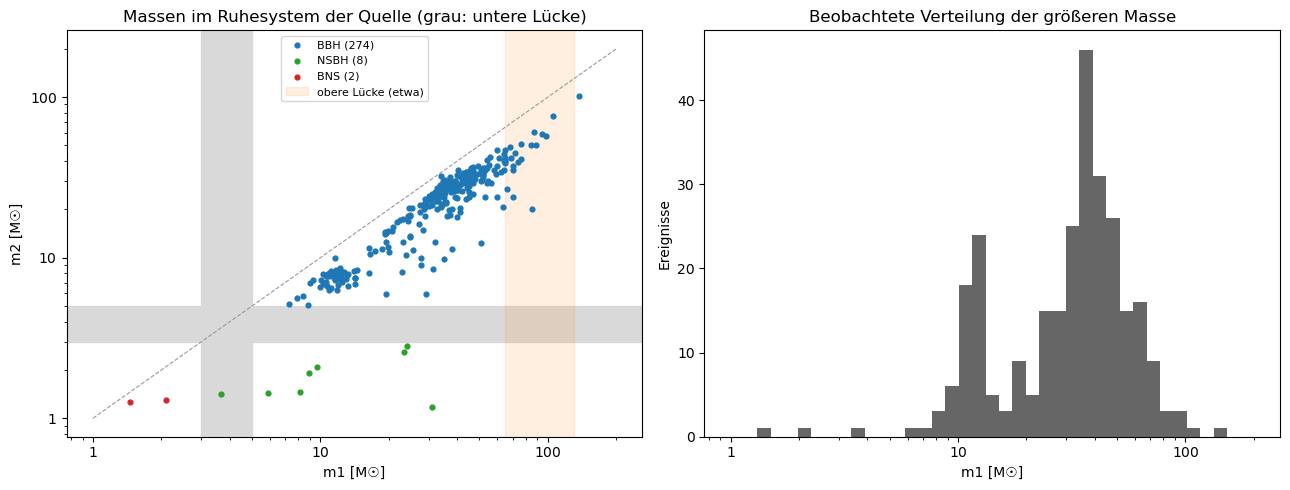

In [13]:
gwtc.masses()

**13. Entfernung und Masse**

Die Entfernung jedes Ereignisses gegen seine Chirp-Masse im Detektor, nach Kampagne gefärbt. Die Reichweite, bis zu der ein System nachweisbar ist, sollte wie Masse^(5/6) wachsen; die gestrichelte Linie zeigt das, angelegt an die O4-Ereignisse.

Die mittlere Entfernung stieg von 470 Mpc in O1 auf 2400 Mpc in O4, die größte bis 8.3 Gpc. Die obere Kante der Punkte folgt ungefähr der Linie: Doppelte Masse heißt 2^(5/6) ≈ 1.8-fache Reichweite. Die leichtesten Systeme sieht man nur in der Nähe. Über etwa 60 Sonnenmassen bleiben die Punkte unter der Linie, weil das Einspiralen dort unterhalb des empfindlichen Frequenzbands endet.

            n  dl_median  dl_max  z_max  mc_det_median
kampagne                                              
O1          3      470.0  1000.0   0.20          18.72
O2          8     1075.0  2490.0   0.44          28.62
O3         80     1770.0  8280.0   1.18          33.41
O4        193     2400.0  7300.0   1.06          36.51


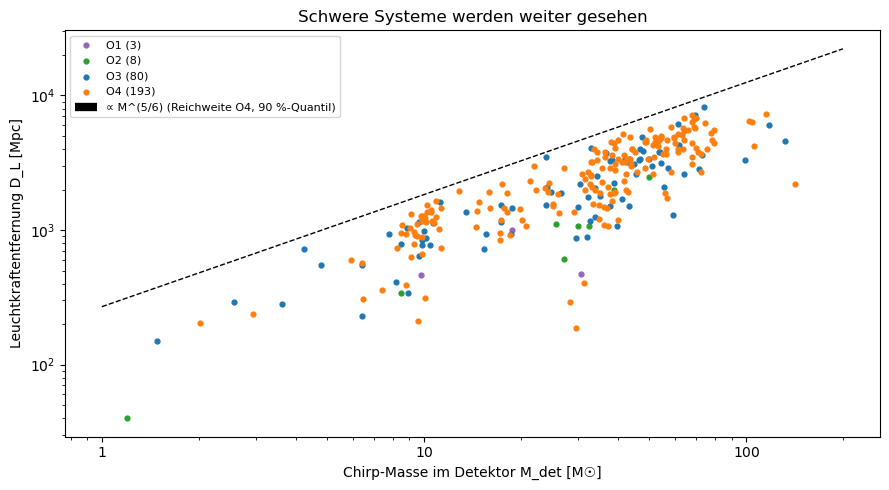

In [14]:
gwtc.distances()

**14. Ein Ereignis aus dem Katalog ansehen**

Ein frei gewähltes Ereignis in den Rohdaten, voreingestellt das lauteste, GW250114: 32 Sekunden von H1, geweißt und als Zeit-Frequenz-Bild wie bei GW150914. Aus der Chirp-Masse folgt vorab, wie lange das Signal ab 30 Hz dauert.

Von 30 Hz bis zur Verschmelzung vergehen nur 0.24 s. Der Chirp beginnt bei etwa −0.18 s und steigt bis kurz nach t = 0 auf über 300 Hz; er ist deutlich heller und breiter als bei GW150914, weil die Detektoren in O4 empfindlicher sind. Der helle Fleck bei etwa −0.3 s und 30 bis 60 Hz liegt nicht auf der Chirp-Kurve; er ist eine Schwankung im Rauschen.

GW250114_082203 (GWTC-5.0): GPS 1420878141.2, Detektoren ['H1', 'L1'], verwendet H1
m1 = 33.76, m2 = 32.26 M☉, Chirp-Masse 28.710 M☉ (im Detektor 31.294), D_L = 405 Mpc, SNR = 78.6
Zeit von 30 Hz bis zur Verschmelzung: 0.24 s


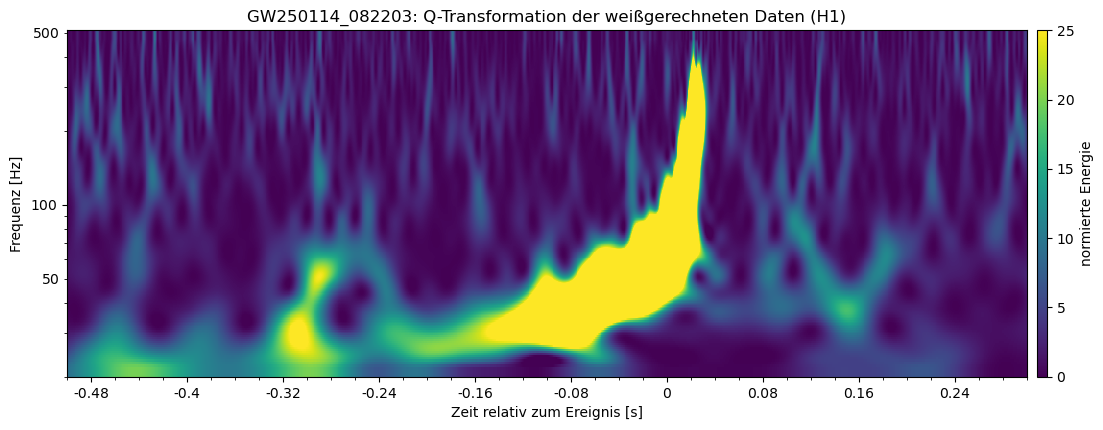

In [15]:
gwtc.event_spectrogram()

**15. Signalstärke, Masse und die Reichweite der Detektoren**

SNR mal Entfernung hängt nur noch von Masse und Detektor ab und sollte wie Masse^(5/6) wachsen. Angepasst wird eine Gerade im doppelt logarithmischen Bild, mit einem eigenen Achsenabschnitt je Kampagne; der Abstand der Geraden ist das Verhältnis der Reichweiten.

Für die leichtesten Systeme ist die Steigung 0.85 ± 0.07, wie erwartet (5/6 = 0.83); mit allen Ereignissen sinkt sie auf 0.75, weil bei schweren Systemen das Einspiralen unterhalb des Bandes endet. Die Reichweite relativ zu O3 war 0.63 in O1, 0.69 in O2 und 1.26 in O4: Von O1 bis O4 hat sie sich verdoppelt, das beobachtete Volumen etwa verachtfacht.

M_det <   10 M☉ (n =  44): Steigung s = 0.85 ± 0.07  (erwartet 5/6 = 0.83), Streuung ±0.09 dex
M_det <   20 M☉ (n =  88): Steigung s = 0.78 ± 0.05  (erwartet 5/6 = 0.83), Streuung ±0.10 dex
M_det < 1000 M☉ (n = 284): Steigung s = 0.75 ± 0.02  (erwartet 5/6 = 0.83), Streuung ±0.10 dex

Reichweite relativ zu O3 (aus den Ereignissen mit M_det < 20 M☉): O1 0.63, O2 0.69, O3 1.00, O4 1.26


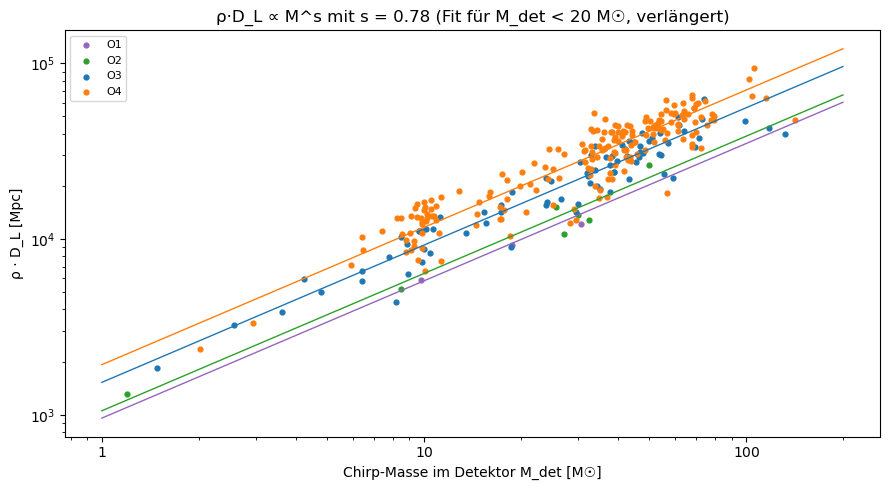

In [16]:
gwtc.snr_scaling()

**16. Der Auswahleffekt**

Schwere Paare sind lauter und werden in einem viel größeren Volumen gefunden; der Katalog überschätzt sie (Malmquist-Bias). Jedes Paar wird deshalb mit 1/V_max gewichtet, dem Kehrwert des Volumens, in dem es noch nachweisbar gewesen wäre.

Beobachtet haben 20 % der Paare eine größere Masse unter 15 Sonnenmassen, gewichtet 73 %. Leichte Systeme sieht man im Median bis 1.4 Gpc, schwere bis 4.6 Gpc, in einem etwa 35-mal größeren Volumen. Gewichtet fällt die Verteilung von 10 nach 100 Sonnenmassen um mehr als drei Größenordnungen, mit dem Maximum bei 9 bis 12 und einer kleinen Erhebung bei 30 bis 35: Schwere schwarze Löcher sind in der Natur selten.

    m1  beobachtet  Anteil beobachtet  Anteil gewichtet  gewichtet pro M☉
   5-7           0             0.0000            0.0000            0.0000
   7-9           4             0.0146            0.0889            0.0444
  9-12          30             0.1095            0.4365            0.1455
 12-15          20             0.0730            0.2081            0.0694
 15-20          12             0.0438            0.0762            0.0152
 20-25          16             0.0584            0.0459            0.0092
 25-30          18             0.0657            0.0337            0.0067
 30-35          32             0.1168            0.0548            0.0110
 35-40          41             0.1496            0.0318            0.0064
 40-50          48             0.1752            0.0135            0.0014
 50-65          30             0.1095            0.0055            0.0004
 65-80          15             0.0547            0.0045            0.0003
80-150           8             0.0292 

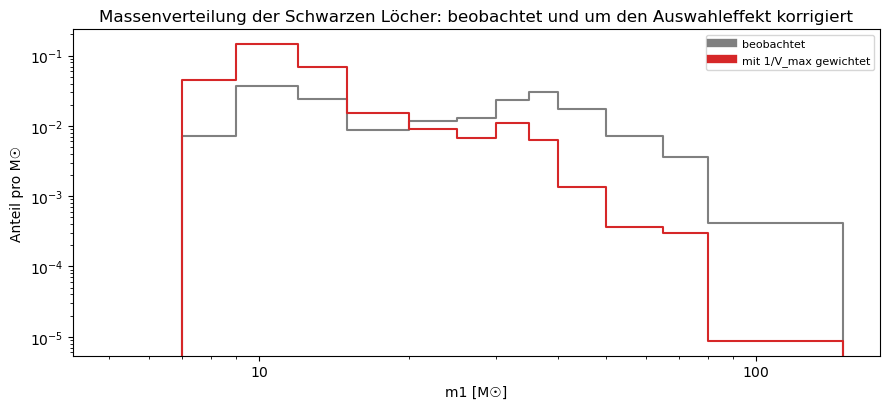

In [17]:
gwtc.mass_distribution()

**17. Vergleich mit dem Katalog und der Literatur**

Die Chirp-Masse aus den Katalogwerten der beiden Massen gegen den Katalogwert der Chirp-Masse; die eigenen Reichweiten gegen die veröffentlichten Reichweiten von LIGO; die Maxima der gewichteten Verteilung gegen die Populationsanalyse der Kollaboration.

Die selbst berechnete Chirp-Masse liegt im Median 0.9 % über dem Katalog, weil der Median einer Funktion nicht die Funktion der Mediane ist; am größten ist der Unterschied mit 16 % bei einem Ereignis mit kaum bestimmten Massen. Die Reichweiten passen zu den veröffentlichten (O1 zu O3 etwa 75 zu 120 Mpc). Die Maxima bei 10 und 35 Sonnenmassen findet auch die viel aufwendigere Analyse der Kollaboration.

In [18]:
gwtc.literature()

Chirp-Masse aus den Medianen von m1, m2 geteilt durch den Katalogwert: Median 1.009, 5–95 % 0.998 bis 1.028
  größte Abweichung: GW200322_091133 (1.162); m1 = 38.0, m2 = 11.3, Katalog-Mc = 15.0

Reichweite relativ zu O3:
            eigene Messung    BNS-Reichweite LIGO (etwa)
  O1                  0.63                     70–80 Mpc
  O2                  0.69                    60–100 Mpc
  O3                  1.00                   110–130 Mpc
  O4                  1.26                   150–160 Mpc

Gewichtete Verteilung von m1: lokale Maxima bei 9-12 M☉, 30-35 M☉ 
LVK (GWTC-3, Populationsanalyse): Häufungen bei etwa 10 und 35 M☉
